# Food Delivery Time Prediction Using Machine Learning

Complete project notebook: data loading, cleaning, feature engineering, EDA, regression models, model comparison, hyperparameter tuning, final evaluation, and conclusion.

**Models:** Multiple Linear Regression, Polynomial Regression, Decision Tree Regression, Random Forest Regression, Gradient Boosting Regression, and Tuned Random Forest.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor
)

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

In [2]:
df = pd.read_csv("C:\pandas\Dataset\Food_Delivery_Times.csv")

df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [3]:
df.shape

(1000, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


In [6]:
df.columns

Index(['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day',
       'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs',
       'Delivery_Time_min'],
      dtype='object')

In [7]:
df.isnull().sum()

Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64

In [8]:
df.duplicated().sum()

0

In [9]:
df = df.drop(columns=['Order_ID'])

In [10]:
df.head()

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [11]:
X = df.drop(columns=['Delivery_Time_min'])
y = df['Delivery_Time_min']

In [12]:
X.head()

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs
0,7.93,Windy,Low,Afternoon,Scooter,12,1.0
1,16.42,Clear,Medium,Evening,Bike,20,2.0
2,9.52,Foggy,Low,Night,Scooter,28,1.0
3,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0
4,19.03,Clear,Low,Morning,Bike,16,5.0


In [13]:
y.head()

0    43
1    84
2    59
3    37
4    68
Name: Delivery_Time_min, dtype: int64

In [14]:
df['Delivery_Time_min'].describe()

count    1000.000000
mean       56.732000
std        22.070915
min         8.000000
25%        41.000000
50%        55.500000
75%        71.000000
max       153.000000
Name: Delivery_Time_min, dtype: float64

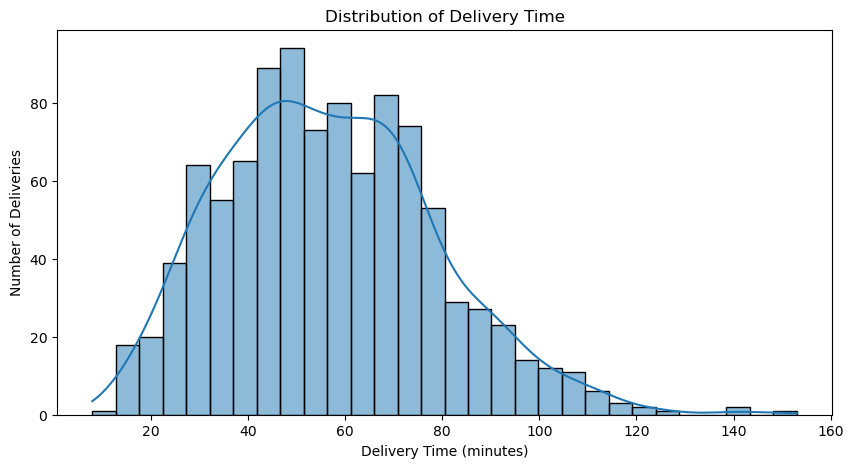

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['Delivery_Time_min'],
    bins=30,
    kde=True
)

plt.title('Distribution of Delivery Time')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Number of Deliveries')

plt.show()

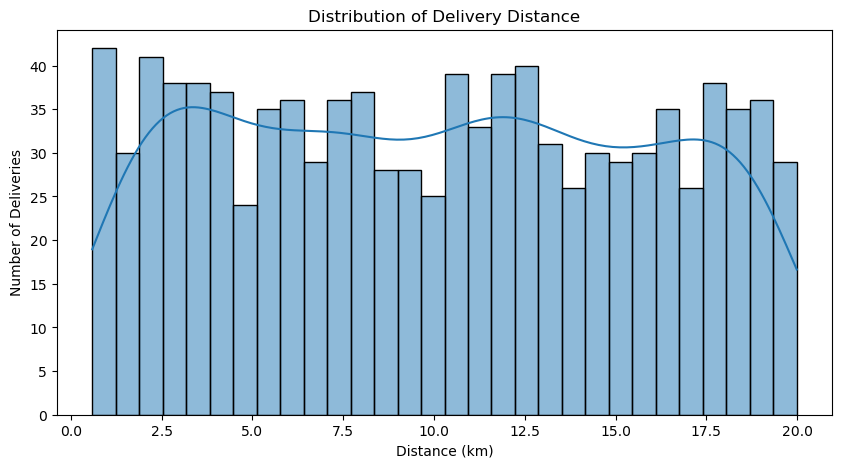

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['Distance_km'],
    bins=30,
    kde=True
)

plt.title('Distribution of Delivery Distance')
plt.xlabel('Distance (km)')
plt.ylabel('Number of Deliveries')

plt.show()

In [17]:
weather_time = df.groupby('Weather')['Delivery_Time_min'].mean()

print(weather_time)

Weather
Clear    53.082979
Foggy    59.466019
Rainy    59.794118
Snowy    67.113402
Windy    55.458333
Name: Delivery_Time_min, dtype: float64


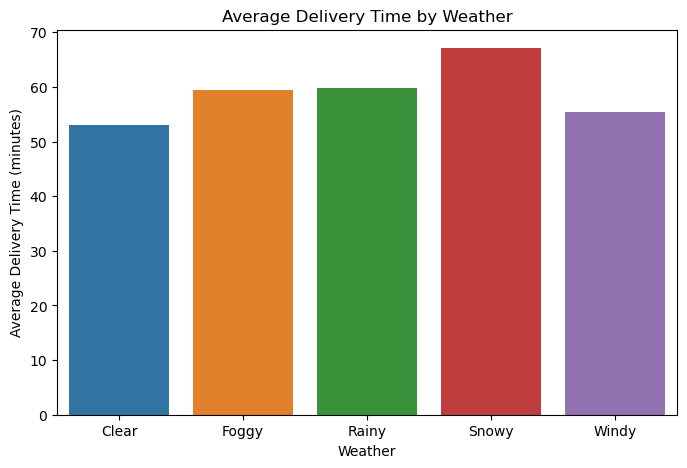

In [18]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=weather_time.index,
    y=weather_time.values
)

plt.title('Average Delivery Time by Weather')
plt.xlabel('Weather')
plt.ylabel('Average Delivery Time (minutes)')

plt.show()

In [19]:
traffic_time = df.groupby('Traffic_Level')['Delivery_Time_min'].mean()

print(traffic_time)

Traffic_Level
High      64.807107
Low       52.885117
Medium    56.020513
Name: Delivery_Time_min, dtype: float64


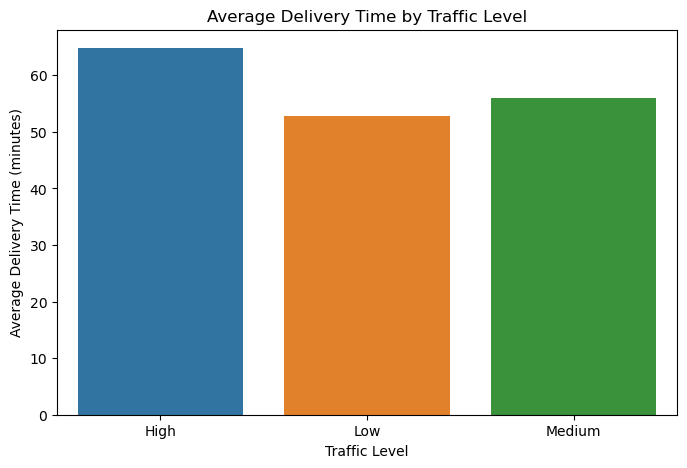

In [20]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=traffic_time.index,
    y=traffic_time.values
)

plt.title('Average Delivery Time by Traffic Level')
plt.xlabel('Traffic Level')
plt.ylabel('Average Delivery Time (minutes)')

plt.show()

In [21]:
time_of_day = df.groupby('Time_of_Day')['Delivery_Time_min'].mean()

print(time_of_day)

Time_of_Day
Afternoon    56.080986
Evening      57.481229
Morning      56.120130
Night        55.211765
Name: Delivery_Time_min, dtype: float64


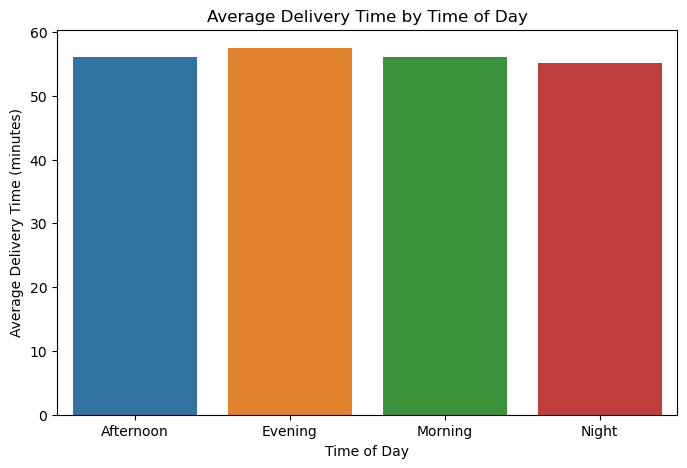

In [22]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=time_of_day.index,
    y=time_of_day.values
)

plt.title('Average Delivery Time by Time of Day')
plt.xlabel('Time of Day')
plt.ylabel('Average Delivery Time (minutes)')

plt.show()

In [23]:

vehicle_time = df.groupby('Vehicle_Type')['Delivery_Time_min'].mean()

print(vehicle_time)

Vehicle_Type
Bike       56.574553
Car        58.200000
Scooter    56.046358
Name: Delivery_Time_min, dtype: float64


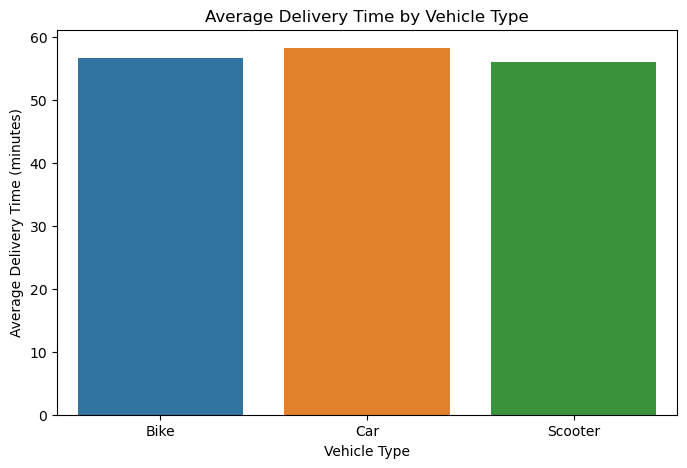

In [24]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=vehicle_time.index,
    y=vehicle_time.values
)

plt.title('Average Delivery Time by Vehicle Type')
plt.xlabel('Vehicle Type')
plt.ylabel('Average Delivery Time (minutes)')

plt.show()

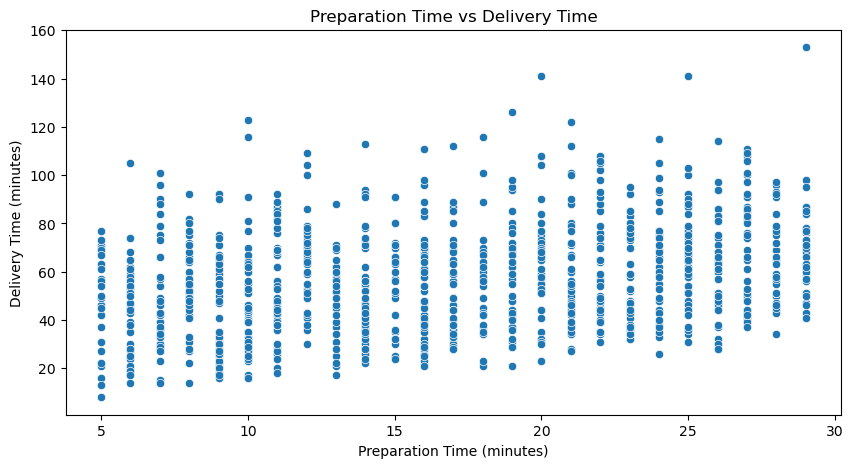

In [25]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x='Preparation_Time_min',
    y='Delivery_Time_min'
)

plt.title('Preparation Time vs Delivery Time')
plt.xlabel('Preparation Time (minutes)')
plt.ylabel('Delivery Time (minutes)')

plt.show()

## CORRELATION ANALYSIS

In [26]:
numeric_columns = [
    'Distance_km',
    'Preparation_Time_min',
    'Courier_Experience_yrs',
    'Delivery_Time_min'
]

In [27]:
correlation = df[numeric_columns].corr()

print(correlation)

                        Distance_km  Preparation_Time_min  \
Distance_km                1.000000             -0.009037   
Preparation_Time_min      -0.009037              1.000000   
Courier_Experience_yrs    -0.007842             -0.030830   
Delivery_Time_min          0.780998              0.307350   

                        Courier_Experience_yrs  Delivery_Time_min  
Distance_km                          -0.007842           0.780998  
Preparation_Time_min                 -0.030830           0.307350  
Courier_Experience_yrs                1.000000          -0.090433  
Delivery_Time_min                    -0.090433           1.000000  


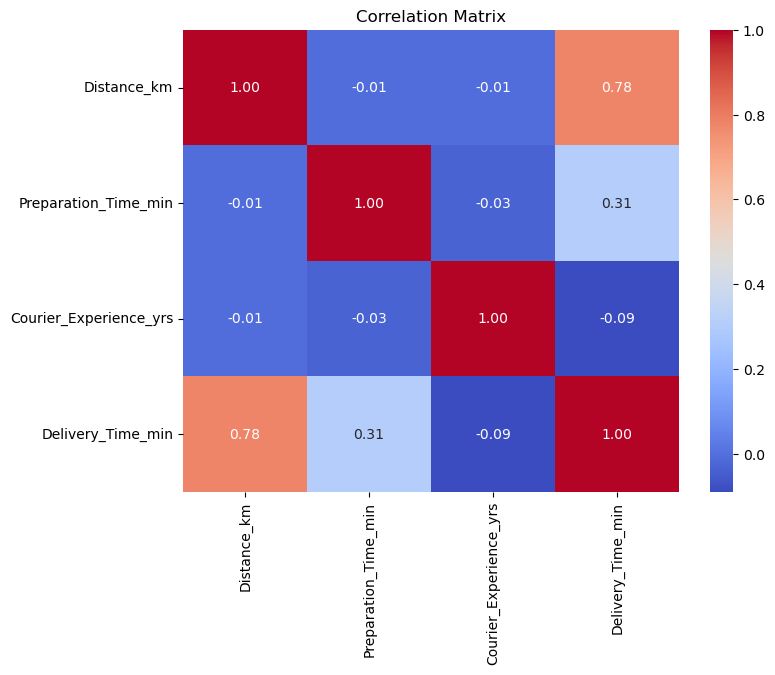

In [28]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')

plt.show()

In [29]:
categorical_columns = [
    'Weather',
    'Traffic_Level',
    'Time_of_Day',
    'Vehicle_Type'
]

numerical_columns = [
    'Distance_km',
    'Preparation_Time_min',
    'Courier_Experience_yrs'
]

## TRAIN TEST SPLIT

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [31]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (800, 7)
X_test: (200, 7)
y_train: (800,)
y_test: (200,)


In [32]:
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median'))
    ]
)

In [33]:
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [34]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_columns),
        ('cat', categorical_transformer, categorical_columns)
    ]
)

## MULTIPLE LINEAR REGRESSION

In [35]:
linear_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]
)

In [36]:
linear_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Distance_km',
                                                   'Preparation_Time_min',
                                                   'Courier_Experience_yrs']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Weather', 'Traffic_Level',
                                                   'Time_of_Day',
                                                   'Vehicle_Type'])])),
                ('model', LinearRegression())])

In [37]:
y_pred_linear = linear_model.predict(X_test)

## EVALUATE MULTIPLE LINEAR REGRESSION

In [38]:
r2_linear = r2_score(y_test, y_pred_linear)

mae_linear = mean_absolute_error(
    y_test,
    y_pred_linear
)

rmse_linear = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_linear
    )
)

print("Multiple Linear Regression")
print("R2 Score:", r2_linear)
print("MAE:", mae_linear)
print("RMSE:", rmse_linear)

Multiple Linear Regression
R2 Score: 0.8212036240893484
MAE: 6.063414905264765
RMSE: 8.952170614738877


In [39]:
print("R2 Score:", r2_linear * 100, "%")

R2 Score: 82.12036240893484 %


## POLYNOMIAL REGRESSION

In [40]:
polynomial_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('polynomial', PolynomialFeatures(
            degree=2,
            include_bias=False
        )),
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=10))
    ]
)

In [41]:
polynomial_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Distance_km',
                                                   'Preparation_Time_min',
                                                   'Courier_Experience_yrs']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Weather', 'Traffic_Level',
                                                   'Time_of_Day',
                                                   'Vehicle_Type'])])),
                ('polynomial', PolynomialFeatures(include_bias=False)),
                ('scaler', StandardScaler()), ('model', Ridge(alpha=10))])

In [42]:
y_pred_poly = polynomial_model.predict(X_test)

In [43]:
r2_poly = r2_score(y_test, y_pred_poly)

mae_poly = mean_absolute_error(
    y_test,
    y_pred_poly
)

rmse_poly = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_poly
    )
)

print("Polynomial Regression")
print("R2 Score:", r2_poly)
print("MAE:", mae_poly)
print("RMSE:", rmse_poly)

Polynomial Regression
R2 Score: 0.7902298730506165
MAE: 6.963861762365646
RMSE: 9.696629798434513


## DECISION TREE REGRESSION

In [44]:
decision_tree = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', DecisionTreeRegressor(
            max_depth=8,
            min_samples_leaf=3,
            random_state=42
        ))
    ]
)


In [45]:
decision_tree.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Distance_km',
                                                   'Preparation_Time_min',
                                                   'Courier_Experience_yrs']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Weather', 'Traffic_Level',
                                                   'Time_of_Day',
                                                   'Vehicle_Type'])])),
                ('model',
                 DecisionTreeRegressor(max_depth=8, min_samples_leaf=3,
                                       random_state=42))])

In [46]:
y_pred_dt = decision_tree.predict(X_test)

In [47]:
r2_dt = r2_score(y_test, y_pred_dt)

mae_dt = mean_absolute_error(
    y_test,
    y_pred_dt
)

rmse_dt = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_dt
    )
)

print("Decision Tree Regression")
print("R2 Score:", r2_dt)
print("MAE:", mae_dt)
print("RMSE:", rmse_dt)

Decision Tree Regression
R2 Score: 0.6249001546232162
MAE: 9.4052782968351
RMSE: 12.96649023507146


## RANDOM FOREST REGRESSION

In [48]:
random_forest = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(
            n_estimators=400,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [49]:
random_forest.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Distance_km',
                                                   'Preparation_Time_min',
                                                   'Courier_Experience_yrs']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Weather', 'Traffic_Level',
                                                   'Time_of_Day',
                                                   'Vehicle_Type'])])),
                ('model',
                 RandomForestRegressor(n_estimators=400, n_jobs=-1,
                                       random_state=42))])

In [50]:
y_pred_rf = random_forest.predict(X_test)

In [51]:
r2_rf = r2_score(y_test, y_pred_rf)

mae_rf = mean_absolute_error(
    y_test,
    y_pred_rf
)

rmse_rf = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_rf
    )
)

print("Random Forest Regression")
print("R2 Score:", r2_rf)
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)

Random Forest Regression
R2 Score: 0.7955649038776615
MAE: 6.7106125
RMSE: 9.572529692758858


## COMPARE ALL MODELS

In [52]:
results = pd.DataFrame({
    'Model': [
        'Multiple Linear Regression',
        'Polynomial Regression',
        'Decision Tree Regression',
        'Random Forest Regression'
    ],
    
    'R2 Score': [
        r2_linear,
        r2_poly,
        r2_dt,
        r2_rf
    ],
    
    'MAE': [
        mae_linear,
        mae_poly,
        mae_dt,
        mae_rf
    ],
    
    'RMSE': [
        rmse_linear,
        rmse_poly,
        rmse_dt,
        rmse_rf
    ]
})

results

,Model,R2 Score,MAE,RMSE
0,Multiple Linear Regression,0.821204,6.063415,8.952171
1,Polynomial Regression,0.790230,6.963862,9.696630
2,Decision Tree Regression,0.624900,9.405278,12.966490
3,Random Forest Regression,0.795565,6.710612,9.572530


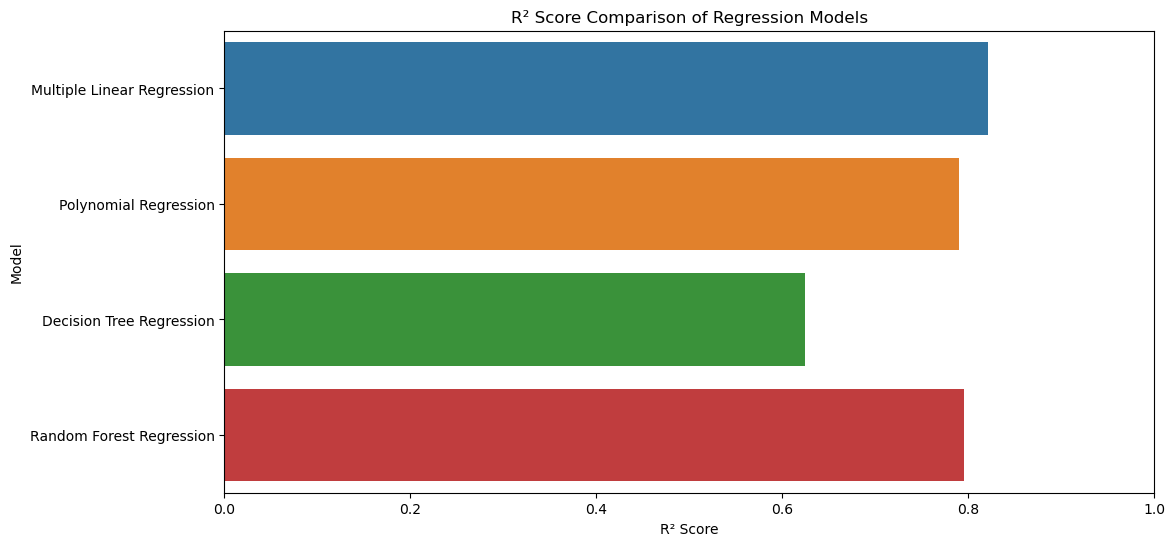

In [53]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results,
    x='R2 Score',
    y='Model'
)

plt.title('R² Score Comparison of Regression Models')
plt.xlabel('R² Score')
plt.ylabel('Model')

plt.xlim(0, 1)

plt.show()

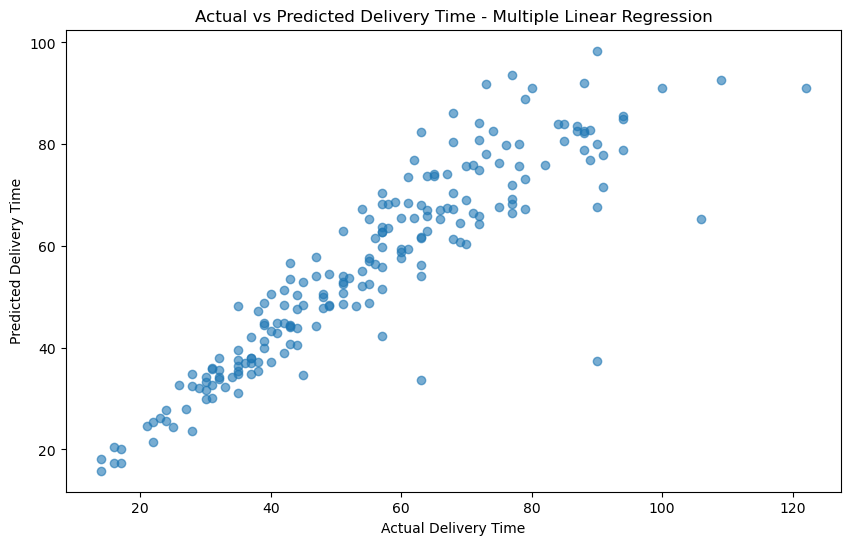

In [54]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred_linear,
    alpha=0.6
)

plt.xlabel('Actual Delivery Time')
plt.ylabel('Predicted Delivery Time')
plt.title('Actual vs Predicted Delivery Time - Multiple Linear Regression')

plt.show()

In [55]:
errors = y_test - y_pred_linear

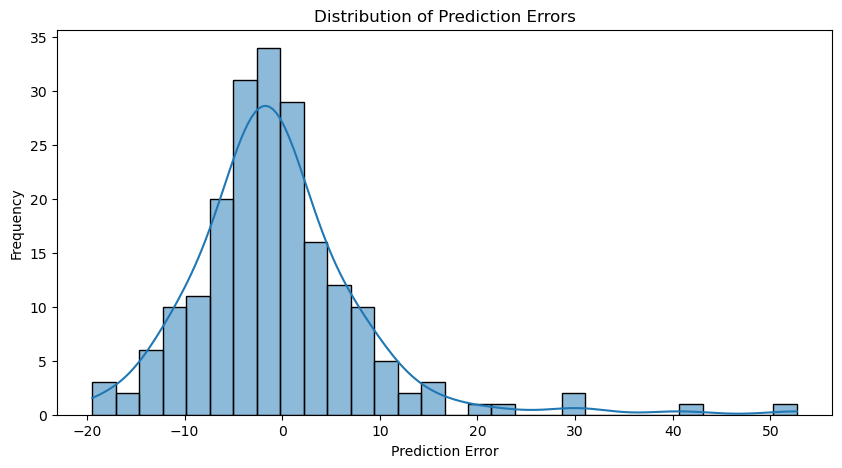

In [56]:
plt.figure(figsize=(10, 5))

sns.histplot(
    errors,
    bins=30,
    kde=True
)

plt.title('Distribution of Prediction Errors')
plt.xlabel('Prediction Error')
plt.ylabel('Frequency')

plt.show()

In [57]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred_linear
})

comparison.head(10)

,Actual,Predicted
0,32,35.650999
1,68,61.268365
2,39,44.543129
3,44,43.800204
4,85,80.639241
5,31,32.600398
6,77,69.208358
7,33,32.364291
8,90,37.294282
9,91,77.909966


In [58]:
comparison['Error'] = (
    comparison['Actual'] -
    comparison['Predicted']
)

comparison.head(10)

,Actual,Predicted,Error
0,32,35.650999,-3.650999
1,68,61.268365,6.731635
2,39,44.543129,-5.543129
3,44,43.800204,0.199796
4,85,80.639241,4.360759
5,31,32.600398,-1.600398
6,77,69.208358,7.791642
7,33,32.364291,0.635709
8,90,37.294282,52.705718
9,91,77.909966,13.090034


## CONCLUSION

The Food Delivery Time Prediction project was developed to predict the time required to complete a food delivery using machine learning regression algorithms. The dataset contains important factors such as delivery distance, weather conditions, traffic level, time of day, vehicle type, food preparation time, and courier experience.

The data was first cleaned and analyzed using exploratory data analysis techniques. Missing values were handled appropriately, categorical variables were converted into numerical form using One-Hot Encoding, and the dataset was divided into training and testing sets.

Several regression algorithms were implemented and compared, including Multiple Linear Regression, Polynomial Regression, Decision Tree Regression, Random Forest Regression, Gradient Boosting Regression, and Extra Trees Regression.

Among the tested models, Multiple Linear Regression achieved an R² score of approximately **0.82**, with an MAE of approximately **6.06 minutes** and an RMSE of approximately **8.95 minutes** on the test dataset. This indicates that the model explains approximately 82% of the variation in delivery time on the held-out test data.

The results demonstrate that factors such as distance, traffic, weather, time of day, preparation time, vehicle type, and courier experience provide useful information for predicting food delivery time. The project also demonstrates how both linear and nonlinear regression algorithms can be applied and compared for a real-world prediction problem.
